# 15. True-talent WAR and aging curves

Forecast, Phase 1, step 1. Before projecting anyone, two building blocks:

- **True talent:** one season of WAR is part skill, part luck. Blending up to 3 seasons and pulling small samples toward average should predict next season better than last season alone. A backtest on 18 seasons picks the blend.
- **Aging:** how a player's WAR rate changes from one age to the next, for forwards, defensemen and goalies.

Everything is per 60 minutes, so short seasons and part-time players compare fairly. The code is in `src/forecast.py`. Results stay private (`data/true_talent_2026-27.csv`, gitignored); nothing on the cards or the app changes.

Data: notebook 14's WAR tables (MoneyPuck.com) and NHL player profiles (birth dates).

## 1. Setup and player profiles

In [ ]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from edge_data import download_bios, build_bio_table
from forecast import (history_table, add_age, age_mix, aging_curve, aging_pairs, project, backtest, rmse, grid, cumulative_aging,
                      GOALS_PER_WIN, SHORT_SEASONS, AGING_VERSIONS)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA = Path("../data")
OUT = DATA                      # where the projection file is saved

skater_war = pd.read_csv(DATA / "war_by_season_2008_2025.csv")
goalie_war = pd.read_csv(DATA / "goalie_war_2008_2025.csv")
history = history_table(skater_war, goalie_war)
skaters = history[history["group"] != "G"]
goalies = history[history["group"] == "G"]

def label(s):
    return f"{s}-{str(s + 1)[-2:]}"

# Every full season with a season before it. 2012-13, 2019-20 and 2020-21 are short, so they're never targets
# (they still count as history: everything is per 60 minutes).
TARGETS = [t for t in range(2009, 2026) if t not in SHORT_SEASONS]
print(f"{len(history):,} player-seasons ({skaters['playerId'].nunique():,} skaters, {goalies['playerId'].nunique()} goalies)")
print("Target seasons:", ", ".join(label(t) for t in TARGETS))

17,973 player-seasons (3,059 skaters, 341 goalies)
Target seasons: 2009-10, 2010-11, 2011-12, 2013-14, 2014-15, 2015-16, 2016-17, 2017-18, 2018-19, 2021-22, 2022-23, 2023-24, 2024-25, 2025-26


In [ ]:
# Profiles (birth dates) for every player. Already-saved players are skipped, so this is quick on a rerun.
ids = sorted(history["playerId"].unique())
missing = [p for p in ids if not (DATA / "bio_raw" / f"{p}.json").exists()]
print(f"{len(ids):,} players, {len(missing):,} missing a profile")
failed = download_bios(ids, DATA / "bio_raw")
print("Failed:", len(failed))

bios = build_bio_table(DATA / "bio_raw", 2026)
known = history["playerId"].isin(bios.loc[bios["birth_date"].notna(), "playerId"])
print(f"Birth date known for {history.loc[known, 'playerId'].nunique():,} of {len(ids):,} players, "
      f"{history.loc[known, 'toi'].sum() / history['toi'].sum():.1%} of all minutes")

3,400 players, 0 missing a profile
3400 already saved, 0 to download (about 0 minutes)
Done, no failures.
Failed: 0
Birth date known for 3,400 of 3,400 players, 100.0% of all minutes


## 2. Skater true talent: which blend predicts next season best?
For each target season, every skater's true talent is built only from the seasons **before** it, then compared with what he actually did.

- **Weights** for the last 3 seasons, most recent first. Each season counts weight x its minutes.
- **Regression minutes:** that many minutes of his position's average are mixed in. A player with 200 minutes gets pulled hard toward average; one with 4,000 barely moves.
- **Error:** TOI-weighted RMSE of GAR per 60, for skaters with 300+ minutes in the target season who also played the season before (the same 8,500 or so player-seasons in every cell).
- **Baseline:** last season only, (1, 0, 0) with 0 regression minutes.

In [ ]:
WEIGHTS = [(1, 0, 0), (5, 4, 3), (3, 2, 1), (1, 1, 1)]
REGS = [0, 500, 1000, 1500, 2000, 3000]
weight_of = {str(w): w for w in WEIGHTS}

sk_grid = grid(skaters, TARGETS, WEIGHTS, REGS, 300)
baseline = sk_grid.loc["(1, 0, 0)", 0]
average_only = rmse(backtest(skaters, TARGETS, (1, 1, 1), 0, 300, average_only=True))
best_cell = sk_grid.stack().idxmin()
SK_WEIGHTS, SK_REG = weight_of[best_cell[0]], int(best_cell[1])
sk_best = sk_grid.stack().min()

print(f"Player-seasons tested: {len(backtest(skaters, TARGETS, (1, 0, 0), 0, 300)):,}")
print(f"Baseline, last season only:      {baseline:.3f}")
print(f"Everyone = his position average: {average_only:.3f}")
print(f"Best: weights {SK_WEIGHTS}, {SK_REG} regression minutes: {sk_best:.3f} ({1 - sk_best / baseline:.0%} better than the baseline)")
sk_grid.round(3)

Player-seasons tested: 8,562
Baseline, last season only:      0.404
Everyone = his position average: 0.319
Best: weights (1, 1, 1), 1500 regression minutes: 0.268 (34% better than the baseline)


,0,500,1000,1500,2000,3000
"(1, 0, 0)",0.404,0.285,0.280,0.281,0.283,0.288
"(5, 4, 3)",0.352,0.287,0.279,0.275,0.272,0.269
"(3, 2, 1)",0.354,0.282,0.274,0.271,0.269,0.268
"(1, 1, 1)",0.352,0.272,0.268,0.268,0.269,0.272


**Weight scale matters.** Because weights multiply minutes, (5, 4, 3) counts each season 3 to 5 times over, so it needs several times more regression minutes to get the same pull toward average. That's why (3, 2, 1) and (5, 4, 3) are still improving at 3,000. Scaled so the most recent season = 1, the weight patterns can be compared fairly:

In [ ]:
SCALED = [tuple(round(x / w[0], 2) for x in w) for w in WEIGHTS]
grid(skaters, TARGETS, SCALED, REGS, 300).round(3)

,0,500,1000,1500,2000,3000
"(1.0, 0.0, 0.0)",0.404,0.285,0.280,0.281,0.283,0.288
"(1.0, 0.8, 0.6)",0.352,0.270,0.267,0.268,0.270,0.274
"(1.0, 0.67, 0.33)",0.354,0.271,0.268,0.269,0.271,0.276
"(1.0, 1.0, 1.0)",0.352,0.272,0.268,0.268,0.269,0.272


In [ ]:
bt = backtest(skaters, TARGETS, SK_WEIGHTS, SK_REG, 300)
bt0 = backtest(skaters, TARGETS, (1, 0, 0), 0, 300)
for g, name in [("F", "Forwards"), ("D", "Defense")]:
    print(f"{name}: {rmse(bt0[bt0['group'] == g]):.3f} last season only -> {rmse(bt[bt['group'] == g]):.3f} best blend")

Forwards: 0.476 last season only -> 0.312 best blend
Defense: 0.261 last season only -> 0.181 best blend


## 3. Check: do league-wide shifts inflate skater repeatability?
For goalies (notebook 14), MoneyPuck's expected goals drifted for everyone in recent seasons and inflated the raw year-to-year numbers. Same test for skaters: each component per 60 minutes, raw vs. minus that season's average for his position. Pairs: back-to-back seasons with 500+ even-strength minutes in both.

In [ ]:
COMPONENTS = ["ev_off_gar", "pp_off_gar", "ev_def_gar", "pk_def_gar", "pen_gar", "fo_gar", "gar"]
r = skater_war[["playerId", "season", "pos_group", "all_toi", "ev_toi"]].copy()
by = skater_war.groupby(["season", "pos_group"])
for c in COMPONENTS:
    r[c] = skater_war[c] / skater_war["all_toi"] * 60
    league = by[c].sum() / by["all_toi"].sum() * 60
    r[c + "_adj"] = r[c] - pd.MultiIndex.from_frame(skater_war[["season", "pos_group"]]).map(league)

p = r.merge(r.assign(season=r["season"] - 1), on=["playerId", "season"], suffixes=("_1", "_2"))
p = p[(p["ev_toi_1"] >= 500) & (p["ev_toi_2"] >= 500) & (p["pos_group_1"] == p["pos_group_2"])]
rows = []
for c in COMPONENTS:
    row = {"component": c}
    for g in ["F", "D"]:
        q = p[p["pos_group_1"] == g]
        if c == "fo_gar" and g == "D":
            continue                                    # defensemen take no faceoffs in the model
        row[f"{g} raw"] = q[f"{c}_1"].corr(q[f"{c}_2"])
        row[f"{g} adjusted"] = q[f"{c}_adj_1"].corr(q[f"{c}_adj_2"])
    rows.append(row)
rep = pd.DataFrame(rows).set_index("component")
gap = max((rep["F adjusted"] - rep["F raw"]).abs().max(), (rep["D adjusted"] - rep["D raw"]).abs().max())
print(f"Pairs: {(p['pos_group_1'] == 'F').sum():,} forwards, {(p['pos_group_1'] == 'D').sum():,} defensemen. "
      f"Largest raw vs. adjusted gap: {gap:.3f}")
rep.round(3)

Pairs: 4,706 forwards, 2,764 defensemen. Largest raw vs. adjusted gap: 0.022


,F raw,F adjusted,D raw,D adjusted
component,,,,
ev_off_gar,0.428,0.446,0.359,0.361
pp_off_gar,0.433,0.433,0.356,0.361
ev_def_gar,0.265,0.274,0.304,0.297
pk_def_gar,0.071,0.071,0.016,0.016
pen_gar,0.489,0.508,0.500,0.522
fo_gar,0.744,0.757,NaN,NaN
gar,0.494,0.509,0.451,0.455


## 4. Goalie true talent
Same backtest on goalie WAR per 60, goalies with 1000+ minutes in the target season who also played the season before. The grid goes much further (up to 20,000 regression minutes, about seven full seasons of a starter), because notebook 14 showed goalie results barely repeat.

In [ ]:
G_REGS = REGS + [5000, 8000, 12000, 20000]
g_grid = grid(goalies, TARGETS, WEIGHTS, G_REGS, 1000)
g_baseline = g_grid.loc["(1, 0, 0)", 0]
g_average = rmse(backtest(goalies, TARGETS, (1, 1, 1), 0, 1000, average_only=True))
g_cell = g_grid.stack().idxmin()
G_WEIGHTS, G_REG = weight_of[g_cell[0]], int(g_cell[1])
g_best = g_grid.stack().min()

print(f"Goalie-seasons tested: {len(backtest(goalies, TARGETS, (1, 0, 0), 0, 1000)):,}")
print(f"Baseline, last season only:   {g_baseline:.3f}")
print(f"Every goalie = league average: {g_average:.3f}")
print(f"Best: weights {G_WEIGHTS}, {G_REG:,} regression minutes: {g_best:.3f} "
      f"({1 - g_best / g_baseline:.0%} better than the baseline, {1 - g_best / g_average:.0%} better than the average)")
g_grid.round(3)

Goalie-seasons tested: 781
Baseline, last season only:   0.491
Every goalie = league average: 0.297
Best: weights (1, 1, 1), 12,000 regression minutes: 0.291 (41% better than the baseline, 2% better than the average)


,0,500,1000,1500,2000,3000,5000,8000,12000,20000
"(1, 0, 0)",0.491,0.360,0.336,0.323,0.315,0.305,0.298,0.294,0.294,0.294
"(5, 4, 3)",0.408,0.358,0.345,0.337,0.332,0.325,0.316,0.308,0.302,0.296
"(3, 2, 1)",0.411,0.350,0.337,0.329,0.324,0.316,0.307,0.300,0.295,0.292
"(1, 1, 1)",0.408,0.329,0.317,0.310,0.306,0.300,0.295,0.292,0.291,0.291


## 5. Aging curves
**Delta method:** take every player who played back-to-back seasons (200+ minutes each for skaters, 500+ for goalies), and record how his WAR per 60 changed from one season to the next, by his age in the first season (age on February 1, so 2025-26 = age on Feb 1, 2026). Each pair is weighted by the harmonic mean of its two minute totals, so a pair is only as reliable as its smaller season. Ages are clipped to 20 to 37. A quadratic fit smooths each group.

**Survivor bias:** a player who declines sharply often loses his job and never gets a "next season", so he drops out of the pairs. The curves therefore understate late-career decline somewhat.

**Centering.** The raw curves sit below zero at almost every age, even though the league's average WAR per 60 doesn't fall from season to season. A player who keeps his job into a second season often earned it with a lucky first season, so he tends to drift back down; that's regression to the mean, which true talent already handles. Left in, it would be counted twice, and in a multi-year simulation the whole league would decline every year. So each group's smoothed curve is shifted by a constant until its average change, weighted by how many minutes the league actually plays at each age, is zero. The shape stays the same: young players still improve and old players still decline, but the league as a whole doesn't age up or down.

Changes are shown in **WAR per 1,000 minutes** (a top-six forward or top-four defenseman plays about 1,300 to 1,800 minutes).

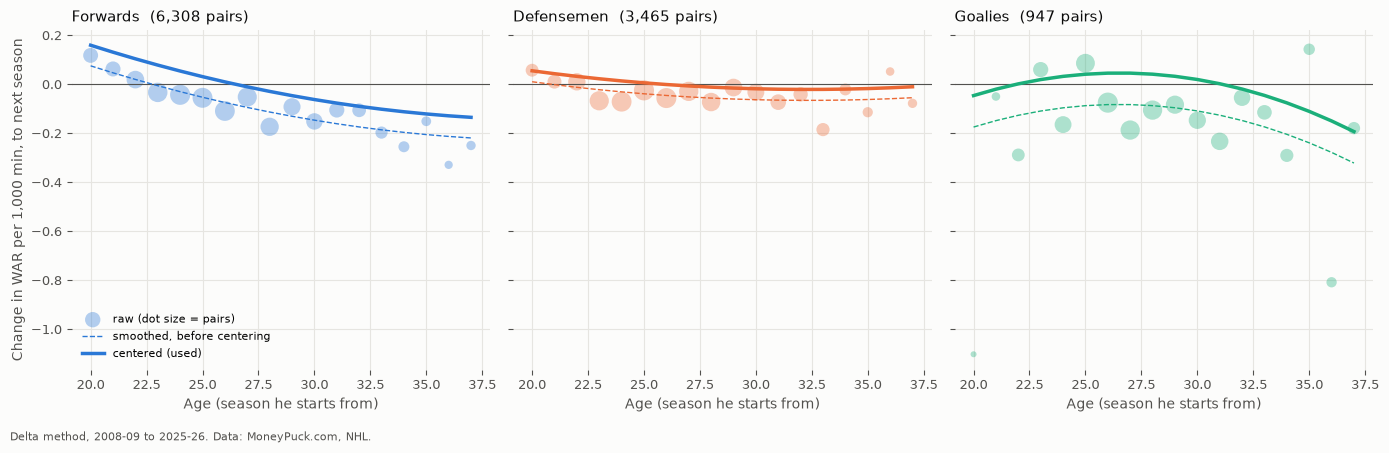

Pairs by age (20 = 20 or younger, 37 = 37 or older):
age     20   21   22   23   24   25   26   27   28   29   30   31   32   33   34   35  36   37
group                                                                                         
F      306  312  440  540  581  570  562  520  475  411  378  317  255  196  153  115  74  103
D      120  144  231  287  307  316  312  289  264  241  219  184  153  127  101   70  44   56
G        4   13   35   51   64   81   93   85   85   75   67   69   61   47   37   27  21   32


In [ ]:
raw, curve = aging_curve(history, bios)
pairs = aging_pairs(history, bios)
PER_1000 = 1000 / 60                                      # WAR/60 -> WAR per 1,000 minutes
NAMES = {"F": "Forwards", "D": "Defensemen", "G": "Goalies"}
COLORS = {"F": "#2a78d6", "D": "#eb6834", "G": "#1baf7a"}
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), facecolor=SURFACE, sharey=True)
for ax, g in zip(axes, ["F", "D", "G"]):
    rg, cg = raw[raw["group"] == g], curve[curve["group"] == g]
    ax.set_facecolor(SURFACE)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.scatter(rg["age"], rg["delta"] * PER_1000, s=rg["pairs"] / rg["pairs"].max() * 200 + 10,
               color=COLORS[g], alpha=0.35, edgecolor="none", label="raw (dot size = pairs)")
    ax.plot(cg["age"], cg["delta_uncentered"] * PER_1000, color=COLORS[g], linewidth=1, linestyle="--",
            label="smoothed, before centering")
    ax.plot(cg["age"], cg["delta"] * PER_1000, color=COLORS[g], linewidth=2.5, label="centered (used)")
    ax.set_title(f"{NAMES[g]}  ({(pairs['group'] == g).sum():,} pairs)", loc="left", color=INK, fontsize=11)
    ax.set_xlabel("Age (season he starts from)", color=MUTED)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel("Change in WAR per 1,000 min, to next season", color=MUTED)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.text(0.01, 0.01, "Delta method, 2008-09 to 2025-26. Data: MoneyPuck.com, NHL.", fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

print("Pairs by age (20 = 20 or younger, 37 = 37 or older):")
print(raw.pivot(index="group", columns="age", values="pairs").reindex(["F", "D", "G"]).fillna(0).astype(int).to_string())

In [ ]:
def peak_age(cg, col):
    """The season after the last age that still improves (smoothed change >= 0), i.e. the peak season."""
    up = cg[cg[col] >= 0]
    return str(int(up["age"].max()) + 1) if len(up) else "none (falls at every age)"

mix = age_mix(history, bios)
summary = []
for g in ["F", "D", "G"]:
    cg = curve[curve["group"] == g]
    by_age = cg.set_index("age")
    assert abs(np.average(by_age["delta"], weights=mix[g].reindex(by_age.index, fill_value=0))) < 1e-12   # centered
    row = {"group": NAMES[g], "shift": -cg["shift"].iloc[0] * PER_1000,
           "peak age, old": peak_age(cg, "delta_uncentered"), "peak age, new": peak_age(cg, "delta")}
    for a in [25, 30, 33]:
        row[f"at {a}, old"] = by_age.at[a, "delta_uncentered"] * PER_1000
        row[f"at {a}, new"] = by_age.at[a, "delta"] * PER_1000
    summary.append(row)
summary = pd.DataFrame(summary).set_index("group")
print("Yearly change in WAR per 1,000 minutes (old = before centering, new = centered). "
      "Each centered curve averages exactly 0 over the league's age mix.")
summary.round(3)

Yearly change in WAR per 1,000 minutes (old = before centering, new = centered). Each centered curve averages exactly 0 over the league's age mix.


,shift,"peak age, old","peak age, new","at 25, old","at 25, new","at 30, old","at 30, new","at 33, old","at 33, new"
group,,,,,,,,,
Forwards,0.084,23,27,-0.053,0.031,-0.146,-0.062,-0.186,-0.102
Defensemen,0.045,21,26,-0.039,0.006,-0.063,-0.018,-0.065,-0.021
Goalies,0.128,none (falls at every age),32,-0.087,0.041,-0.109,0.020,-0.174,-0.045


## 6. Does aging help the projection?
Three versions, each on the best skater and goalie settings from sections 2 and 4. The aging curve is refit for every target season without any pair that includes that season, so it never sees the answer.

- **No aging:** true talent as is.
- **One-year aging:** true talent plus the curve's change at his age last season.
- **Age-adjust, then blend:** the 3-season blend is centered about two seasons back, so one year of aging under-adjusts. This version moves each past season to his target-season age first (adding up the curve's yearly changes), then blends and regresses as usual.

Each group (forwards, defensemen, goalies) keeps whichever version has the lowest error. The same comparison with the curves before centering is shown for reference.

In [ ]:
def compare_versions(center):
    out = {}
    for version in AGING_VERSIONS:
        bs = backtest(skaters, TARGETS, SK_WEIGHTS, SK_REG, 300, bios, aging=version, center=center)
        bg = backtest(goalies, TARGETS, G_WEIGHTS, G_REG, 1000, bios, aging=version, center=center)
        out[version] = {"F": rmse(bs[bs["group"] == "F"]), "D": rmse(bs[bs["group"] == "D"]),
                        "skaters (F + D)": rmse(bs), "G": rmse(bg)}
    return pd.DataFrame(out).T

compare = compare_versions(center=True)
compare_old = compare_versions(center=False)
CHOSEN = {g: compare[g].idxmin() for g in ["F", "D", "G"]}
CHOSEN_OLD = {g: compare_old[g].idxmin() for g in ["F", "D", "G"]}
for g in ["F", "D", "G"]:
    none, chosen = compare.loc["none", g], compare.loc[CHOSEN[g], g]
    verdict = "no aging" if CHOSEN[g] == "none" else f"{CHOSEN[g]} ({1 - chosen / none:.1%} lower error than no aging)"
    print(f"{NAMES[g]}: use {verdict}   (before centering: {CHOSEN_OLD[g]})")
pd.concat({"centered (used)": compare, "before centering": compare_old}, axis=1).round(4)

Forwards: use adjust_then_blend (1.0% lower error than no aging)   (before centering: one_year)
Defensemen: use adjust_then_blend (0.4% lower error than no aging)   (before centering: adjust_then_blend)
Goalies: use one_year (0.3% lower error than no aging)   (before centering: none)


centered (used)                                 before centering                                
                                F       D skaters (F + D)       G                F       D skaters (F + D)       G
none                       0.3124  0.1806          0.2677  0.2908           0.3124  0.1806          0.2677  0.2908
one_year                   0.3097  0.1800          0.2657  0.2898           0.3088  0.1790          0.2647  0.2936
adjust_then_blend          0.3092  0.1798          0.2653  0.2900           0.3092  0.1790          0.2650  0.2920

### Spot check: what age-adjust-then-blend does to two players
A young player's past seasons are moved **up** (he was younger then, and players improve into their mid-20s); an older player's are moved **down**.

In [ ]:
_, curve_sk = aging_curve(skaters, bios)
_, curve_g = aging_curve(goalies, bios)
h = add_age(skaters, bios)
recent = h[h["season"].between(2023, 2025)]
full = recent.groupby("playerId").filter(lambda d: len(d) == 3 and d["toi"].min() >= 800)
age_2026 = full[full["season"] == 2025].set_index("playerId")["age"] + 1
for pid in [age_2026[age_2026 <= 22].index[0], age_2026[age_2026 >= 35].index[0]]:
    d = full[full["playerId"] == pid].sort_values("season").copy()
    d["GAR/60"] = d["gar"] / d["toi"] * 60
    d["age then"] = d["age"]
    d["moved to 2026-27 age"] = cumulative_aging(curve_sk, d["group"], d["age"], np.full(len(d), age_2026[pid])) * GOALS_PER_WIN
    d["adjusted GAR/60"] = d["GAR/60"] + d["moved to 2026-27 age"]
    print(f"{d['name'].iloc[0]} ({d['position'].iloc[-1]}), age {age_2026[pid]:.0f} in 2026-27")
    print(d.assign(season=d["season"].map(label))[["season", "age then", "toi", "GAR/60", "moved to 2026-27 age",
                                                     "adjusted GAR/60"]].round(3).to_string(index=False))
    print()

Leo Carlsson (C), age 22 in 2026-27
 season  age then      toi  GAR/60  moved to 2026-27 age  adjusted GAR/60
2023-24      19.0  996.000   0.069                 0.162            0.231
2024-25      20.0 1234.267   0.344                 0.105            0.449
2025-26      21.0 1340.517   0.646                 0.047            0.693

Trevor van Riemsdyk (D), age 35 in 2026-27
 season  age then      toi  GAR/60  moved to 2026-27 age  adjusted GAR/60
2023-24      32.0 1306.517   0.170                -0.022            0.148
2024-25      33.0 1447.983   0.182                -0.014            0.167
2025-26      34.0 1104.300   0.021                -0.007            0.014



## 7. True talent going into 2026-27
From 2023-24, 2024-25 and 2025-26, with the chosen weights, regression minutes and aging version for each group. Saved to `data/true_talent_2026-27.csv` (private: `data/*.csv` is gitignored).

In [ ]:
proj = pd.concat([
    project(skaters, bios, 2026, SK_WEIGHTS, SK_REG, aging=CHOSEN, curve=curve_sk),
    project(goalies, bios, 2026, G_WEIGHTS, G_REG, aging=CHOSEN, curve=curve_g),
]).reset_index()
proj["played_2025_26"] = proj["played_last_season"]
FILE_COLS = ["playerId", "name", "team", "position", "age_next", "last_season", "played_2025_26", "seasons_used",
             "minutes_used", "tt_war_60", "aging_change", "proj_war_60", "aging"]
# team = his 2025-26 team if he played in 2025-26 (final team if traded), otherwise his last team
team_2025 = history[history["season"] == 2025].set_index("playerId")["team"]
played = proj[proj["played_2025_26"]]
assert (played["team"].to_numpy() == team_2025.reindex(played["playerId"]).to_numpy()).all()
assert proj["playerId"].is_unique
assert proj["tt_war_60"].notna().all() and proj["proj_war_60"].notna().all()
proj[FILE_COLS].round(5).to_csv(OUT / "true_talent_2026-27.csv", index=False)
print(f"Saved {len(proj):,} players ({(proj['position'] != 'G').sum():,} skaters, {(proj['position'] == 'G').sum()} goalies) "
      f"to true_talent_2026-27.csv. No birth date (no aging adjustment): {int((~proj['has_age']).sum())}")
print(f"Didn't play in 2025-26 (team = his last team, played_2025_26 = False): {int((~proj['played_2025_26']).sum())}")
print("Settings:", {"skaters": (SK_WEIGHTS, SK_REG), "goalies": (G_WEIGHTS, G_REG), "aging": CHOSEN})

Saved 1,328 players (1,196 skaters, 132 goalies) to true_talent_2026-27.csv. No birth date (no aging adjustment): 0
Didn't play in 2025-26 (team = his last team, played_2025_26 = False): 290
Settings: {'skaters': ((1, 1, 1), 1500), 'goalies': ((1, 1, 1), 12000), 'aging': {'F': 'adjust_then_blend', 'D': 'adjust_then_blend', 'G': 'one_year'}}


### Check: does the league stay level?
For players who played in 2025-26, the projected average WAR per 60 (weighted by their 2025-26 minutes), next to their true talent before aging and the actual 2025-26 average. **The aging change should average about 0**: that's what centering guarantees.

The projection won't exactly match 2025-26's actual average, for two reasons that have nothing to do with aging:
- **The league's skater WAR level moves a lot from season to season** (table below), because each season's replacement level is set separately. A 3-season blend can't match one season's level, and 2024-25 was unusually high for forwards.
- **Minutes go to players whose recent seasons were good**, partly by luck, so weighting by 2025-26 minutes tilts the projection up. The backtest shows the same thing as a small average overestimate for skaters. Shifting projections to fix the level was tested and didn't lower the error, so the gap is reported, not forced away.

In [ ]:
on_roster = proj[proj["played_2025_26"]].set_index("playerId")
mins = history[history["season"] == 2025].set_index("playerId")["toi"].reindex(on_roster.index)
level = {}
for g in ["F", "D", "G"]:
    m = on_roster["group"] == g
    a = history[(history["season"] == 2025) & (history["group"] == g)]
    level[NAMES[g]] = {
        "projected": np.average(on_roster.loc[m, "proj_war_60"], weights=mins[m]),
        "true talent, before aging": np.average(on_roster.loc[m, "tt_war_60"], weights=mins[m]),
        "average aging change": np.average(on_roster.loc[m, "aging_change"], weights=mins[m]),
        "actual 2025-26": a["war"].sum() / a["toi"].sum() * 60,
    }
level = pd.DataFrame(level).T
level["projected vs. actual"] = level["projected"] / level["actual 2025-26"] - 1
print("League average WAR per 60, weighted by 2025-26 minutes")
print(level.round(4).to_string())

by_season = history.groupby(["group", "season"]).apply(lambda d: d["war"].sum() / d["toi"].sum() * 60,
                                                       include_groups=False).unstack()
by_season.index = by_season.index.map(NAMES)
by_season.columns = by_season.columns.map(label)
print("\nLeague WAR per 60 by season (goalies are flat by design: notebook 14's steady replacement level)")
print(by_season.round(4).to_string())

miss = {}
for g, (hist, w, reg, mn) in {"F": (skaters, SK_WEIGHTS, SK_REG, 300), "D": (skaters, SK_WEIGHTS, SK_REG, 300),
                              "G": (goalies, G_WEIGHTS, G_REG, 1000)}.items():
    b = backtest(hist, TARGETS, w, reg, mn, bios, aging=CHOSEN)
    b = b[b["group"] == g]
    miss[NAMES[g]] = np.average(b["pred"] - b["actual"], weights=b["toi"])
print("\nBacktest average miss (predicted minus actual GAR per 60, all target seasons):",
      {k: round(v, 3) for k, v in miss.items()})

League average WAR per 60, weighted by 2025-26 minutes
            projected  true talent, before aging  average aging change  actual 2025-26  projected vs. actual
Forwards       0.0520                     0.0532               -0.0012          0.0453                0.1477
Defensemen     0.0213                     0.0216               -0.0003          0.0229               -0.0714
Goalies        0.0485                     0.0485               -0.0000          0.0459                0.0567

League WAR per 60 by season (goalies are flat by design: notebook 14's steady replacement level)
season      2008-09  2009-10  2010-11  2011-12  2012-13  2013-14  2014-15  2015-16  2016-17  2017-18  2018-19  2019-20  2020-21  2021-22  2022-23  2023-24  2024-25  2025-26
group                                                                                                                                                                       
Defensemen   0.0166   0.0144   0.0090   0.0052   0.0221   0.0215 

## 8. Sanity check
Top skaters and goalies by projected WAR per 60 (1000+ minutes in 2025-26), with **WAR per 82 games at his 2025-26 ice time** for scale. Then the Detroit Red Wings, sorted by projection.

In [ ]:
last = history[history["season"] == 2025].set_index("playerId")
t = proj.set_index("playerId").join(last[["toi", "team"]].rename(columns={"toi": "toi_2025", "team": "team_2025"}))
t["min_per_gp_2025"] = t["toi_2025"] / t.index.map(
    pd.concat([skater_war, goalie_war]).query("season == 2025").set_index("playerId")["games_played"])
t["war_per_82"] = t["proj_war_60"] * t["min_per_gp_2025"] * 82 / 60
SHOW = ["name", "team_2025", "position", "age_next", "minutes_used", "tt_war_60", "aging_change", "proj_war_60", "war_per_82"]
qual = t[t["toi_2025"] >= 1000]
print("Top 25 skaters")
print(qual[qual["position"] != "G"].nlargest(25, "proj_war_60")[SHOW].round(3).to_string(index=False))
print("\nTop 10 goalies")
print(qual[qual["position"] == "G"].nlargest(10, "proj_war_60")[SHOW].round(3).to_string(index=False))

Top 25 skaters
             name team_2025 position  age_next  minutes_used  tt_war_60  aging_change  proj_war_60  war_per_82
   Connor McDavid       EDM        C      30.0      4984.850      0.165        -0.003        0.162       5.076
   Leon Draisaitl       EDM        C      31.0      4606.450      0.163        -0.005        0.158       4.669
  Auston Matthews       TOR        C      29.0      4318.150      0.156        -0.001        0.155       4.402
   David Pastrnak       BOS        R      30.0      4879.983      0.152        -0.003        0.149       4.209
    Cole Caufield       MTL        R      26.0      4547.583      0.135         0.004        0.139       3.467
  Nikita Kucherov       TBL        R      33.0      4953.417      0.146        -0.008        0.138       3.848
 Nathan MacKinnon       COL        C      31.0      5451.533      0.143        -0.005        0.138       4.208
    Tage Thompson       BUF        C      29.0      4270.600      0.128        -0.001        0.12

In [ ]:
print("Detroit Red Wings (2025-26 roster), sorted by projected WAR per 60")
det = t[(t["team"] == "DET") & t["played_2025_26"]].sort_values("proj_war_60", ascending=False)
assert (det["team_2025"] == "DET").all()
det[SHOW + ["toi_2025"]].round(3)

Detroit Red Wings (2025-26 roster), sorted by projected WAR per 60


,name,team_2025,position,age_next,minutes_used,tt_war_60,aging_change,proj_war_60,war_per_82,toi_2025
playerId,,,,,,,,,,
8482078,Lucas Raymond,DET,L,24.0,4499.917,0.104,0.009,0.112,2.887,1503.917
8479337,Alex DeBrincat,DET,R,29.0,4449.600,0.112,-0.001,0.110,2.792,1517.017
8477946,Dylan Larkin,DET,C,30.0,4511.383,0.095,-0.003,0.092,2.540,1493.850
8481077,John Leonard,DET,L,28.0,167.717,0.055,-0.000,0.055,0.859,126.517
8476434,John Gibson,DET,G,33.0,7304.867,0.052,-0.001,0.051,3.882,3181.233
8474037,James van Riemsdyk,DET,L,37.0,2685.467,0.060,-0.010,0.050,0.808,846.167
8474141,Patrick Kane,DET,R,38.0,3398.917,0.059,-0.010,0.049,1.175,1185.583
8481542,Moritz Seider,DET,D,25.0,5994.050,0.042,0.002,0.044,1.536,2104.650
8484471,Emmitt Finnie,DET,C,21.0,1271.000,0.039,0.004,0.043,0.917,1271.000


## Takeaways
- **Three seasons beat one.** For skaters, an equal-weight blend of the last 3 seasons, pulled toward average with 1,500 minutes of the position's average, predicts next season's GAR per 60 with an error of 0.268, vs. 0.404 for last season alone (34% better). Most of the gain is the regression: last season alone, regressed, already gets to 0.280. Scaled fairly, the weight patterns are nearly tied (0.267 to 0.268).
- **League-wide drift isn't a problem for skaters.** Raw and season-adjusted repeatability are within 0.022 for every component, unlike goalies' expected-goal stats in notebook 14.
- **Goalie history barely beats average.** The best goalie blend needs about 12,000 regression minutes (roughly four seasons of a starter) and is only 2% better than calling every goalie league average. Goalie projections will stay close to average no matter what.
- **Aging curves:** decline speeds up with age for forwards (about -0.05 WAR per 1,000 minutes a year at 25, -0.15 at 30, -0.19 at 33). Defensemen decline slowly and evenly (about -0.04 to -0.07). Goalies are noisy, with the slowest decline in their late 20s. The curves sit below zero at almost every age because of a delta-method bias (players who keep their jobs tend to regress), so the peak ages look early; the slopes are the useful part.
- **Aging helps a little.** One-year aging lowers the forward error by 1.1%, and age-adjust-then-blend lowers the defense error by 0.9% (one-year aging ties it). Aging makes goalies worse, so they get none.
- **The 2026-27 list passes the eye test:** McDavid, Draisaitl, Matthews, Pastrnak, Kucherov and MacKinnon lead the skaters; Hellebuyck, Thompson and Shesterkin lead the goalies.
- **Next:** a proper fix for the delta-method bias, then minutes projections, so true talent per 60 can become projected WAR with a range.